# ShortcutScope — Comprehensive Three-Model Evaluation Suite
This notebook performs an official, side-by-side evaluation of all three models on the official test set (5,794 images):
1. **Baseline CNN** (Standard Cross-Entropy — prone to shortcut learning)
2. **Group-Weighted Loss** (Importance weighting mitigation)
3. **Group-Balanced Sampling** (Data resampling mitigation)

Evaluates **Overall Accuracy**, **Worst-Group Accuracy**, **Macro F1 Score**, **Per-Class F1**, and **Group Disparities**.

In [1]:
%run ./dataset.ipynb 
%run ./model.ipynb

Metadata path: E:\Shortcutscope\archive\waterbird_complete95_forest2water2\metadata.csv
Dataset shape: (11788, 6)
Columns: ['img_id', 'img_filename', 'y', 'split', 'place', 'place_filename']

First five rows:
   img_id                                                   img_filename  y  split  place                 place_filename
0       1  001.Black_footed_Albatross/Black_Footed_Albatross_0046_18.jpg  1      2      1          /o/ocean/00002178.jpg
1       2  001.Black_footed_Albatross/Black_Footed_Albatross_0009_34.jpg  1      0      1   /l/lake/natural/00000065.jpg
2       3  001.Black_footed_Albatross/Black_Footed_Albatross_0002_55.jpg  1      2      0  /b/bamboo_forest/00000131.jpg
3       4  001.Black_footed_Albatross/Black_Footed_Albatross_0074_59.jpg  1      0      1          /o/ocean/00001268.jpg
4       5  001.Black_footed_Albatross/Black_Footed_Albatross_0014_89.jpg  1      0      1          /o/ocean/00003147.jpg

Split column data type:
int64

Actual split values:
split
2    5

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Load data pipelines and model architecture
%run ./dataset.ipynb
%run ./model.ipynb

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Evaluation Device: {DEVICE}")
print(f"Test dataset size: {len(test_dataset)}")
print(f"Test loader ready: {'test_loader' in globals()}")

Metadata path: E:\Shortcutscope\archive\waterbird_complete95_forest2water2\metadata.csv
Dataset shape: (11788, 6)
Columns: ['img_id', 'img_filename', 'y', 'split', 'place', 'place_filename']

First five rows:
   img_id                                                   img_filename  y  split  place                 place_filename
0       1  001.Black_footed_Albatross/Black_Footed_Albatross_0046_18.jpg  1      2      1          /o/ocean/00002178.jpg
1       2  001.Black_footed_Albatross/Black_Footed_Albatross_0009_34.jpg  1      0      1   /l/lake/natural/00000065.jpg
2       3  001.Black_footed_Albatross/Black_Footed_Albatross_0002_55.jpg  1      2      0  /b/bamboo_forest/00000131.jpg
3       4  001.Black_footed_Albatross/Black_Footed_Albatross_0074_59.jpg  1      0      1          /o/ocean/00001268.jpg
4       5  001.Black_footed_Albatross/Black_Footed_Albatross_0014_89.jpg  1      0      1          /o/ocean/00003147.jpg

Split column data type:
int64

Actual split values:
split
2    5

In [3]:
# 2. Evaluation Engine for Test Set
def evaluate_model_on_test(model_path, model_name):
    model_path = Path(model_path)
    if not model_path.exists():
        print(f"[-] Checkpoint not found: {model_path}")
        return None

    model = ShortcutScopeCNN(num_classes=2).to(DEVICE)
    checkpoint = torch.load(model_path, map_location=DEVICE, weights_only=True)
    model.load_state_dict(checkpoint)
    model.eval()

    all_labels, all_predictions, all_groups = [], [], []

    with torch.inference_mode():
        for images, labels, groups in test_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)
            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            all_labels.extend(labels.cpu().tolist())
            all_predictions.extend(predictions.cpu().tolist())
            all_groups.extend(groups.cpu().tolist())

    if not all_labels:
        raise ValueError("The test loader returned no examples.")

    all_labels = np.array(all_labels)
    all_predictions = np.array(all_predictions)
    all_groups = np.array(all_groups)

    overall_accuracy = accuracy_score(all_labels, all_predictions)
    overall_macro_f1 = f1_score(all_labels, all_predictions, average="macro", zero_division=0)
    class_f1 = f1_score(all_labels, all_predictions, average=None, zero_division=0)

    group_accuracy = {}
    for group_id in range(4):
        mask = (all_groups == group_id)
        if mask.sum() > 0:
            group_accuracy[group_id] = accuracy_score(all_labels[mask], all_predictions[mask])
        else:
            group_accuracy[group_id] = float("nan")

    valid_group_accs = [v for v in group_accuracy.values() if not np.isnan(v)]
    worst_group_accuracy = min(valid_group_accs) if valid_group_accs else float("nan")
    accuracy_disparity = max(valid_group_accs) - min(valid_group_accs) if valid_group_accs else float("nan")

    return {
        "Model": model_name,
        "Overall Test Accuracy": overall_accuracy,
        "Worst-Group Accuracy": worst_group_accuracy,
        "Overall Macro F1": overall_macro_f1,
        "Landbird F1": class_f1[0],
        "Waterbird F1": class_f1[1],
        "Group 0 Acc (Landbird/Land)": group_accuracy[0],
        "Group 1 Acc (Landbird/Water)": group_accuracy[1],
        "Group 2 Acc (Waterbird/Land)": group_accuracy[2],
        "Group 3 Acc (Waterbird/Water)": group_accuracy[3],
        "Accuracy Disparity": accuracy_disparity
    }

In [4]:
# 3. Run Evaluation on All Three Checkpoints
models_to_evaluate = [
    ("models/baseline_cnn.pt", "Baseline (Standard CE)"),
    ("models/weighted_cnn.pt", "Group-Weighted Loss"),
    ("models/balanced_sampling_cnn.pt", "Group-Balanced Sampling"),
]

all_results = []
for model_path, model_name in models_to_evaluate:
    print(f"Evaluating {model_name} from {model_path}...")
    try:
        result = evaluate_model_on_test(model_path, model_name)
        if result is not None:
            all_results.append(result)
            print(
                f"  -> Acc: {result['Overall Test Accuracy']:.4f} | "
                f"Worst-Group: {result['Worst-Group Accuracy']:.4f} | "
                f"Macro F1: {result['Overall Macro F1']:.4f}"
            )
    except Exception as e:
        print(f"  [-] Failed to evaluate {model_name}: {e}")

if all_results:
    df_comparison = pd.DataFrame(all_results).set_index("Model")
    print("\n" + "=" * 90)
    print("SHORTCUTSCOPE — ALL THREE EXPERIMENTS FINAL TEST COMPARISON")
    print("=" * 90)
    display(df_comparison.round(4))

    results_dir = Path("results")
    results_dir.mkdir(parents=True, exist_ok=True)
    csv_path = results_dir / "all_three_models_test_comparison.csv"
    df_comparison.to_csv(csv_path)
    print(f"\n[+] Saved detailed comparison table to: {csv_path}")
else:
    print("No models were evaluated. Check that checkpoint files exist in models/")

Evaluating Baseline (Standard CE) from models/baseline_cnn.pt...
  -> Acc: 0.5561 | Worst-Group: 0.0374 | Macro F1: 0.4844
Evaluating Group-Weighted Loss from models/weighted_cnn.pt...
  -> Acc: 0.5614 | Worst-Group: 0.0935 | Macro F1: 0.4913
Evaluating Group-Balanced Sampling from models/balanced_sampling_cnn.pt...
  -> Acc: 0.5537 | Worst-Group: 0.4754 | Macro F1: 0.5177

SHORTCUTSCOPE — ALL THREE EXPERIMENTS FINAL TEST COMPARISON


,Overall Test Accuracy,Worst-Group Accuracy,Overall Macro F1,Landbird F1,Waterbird F1,Group 0 Acc (Landbird/Land),Group 1 Acc (Landbird/Water),Group 2 Acc (Waterbird/Land),Group 3 Acc (Waterbird/Water),Accuracy Disparity
Model,,,,,,,,,,
Baseline (Standard CE),0.5561,0.0374,0.4844,0.6766,0.2922,0.9698,0.2235,0.0374,0.7897,0.9325
Group-Weighted Loss,0.5614,0.0935,0.4913,0.6802,0.3025,0.9295,0.2687,0.0935,0.7648,0.8360
Group-Balanced Sampling,0.5537,0.4754,0.5177,0.6494,0.3860,0.5867,0.4754,0.5826,0.6838,0.2084



[+] Saved detailed comparison table to: results\all_three_models_test_comparison.csv


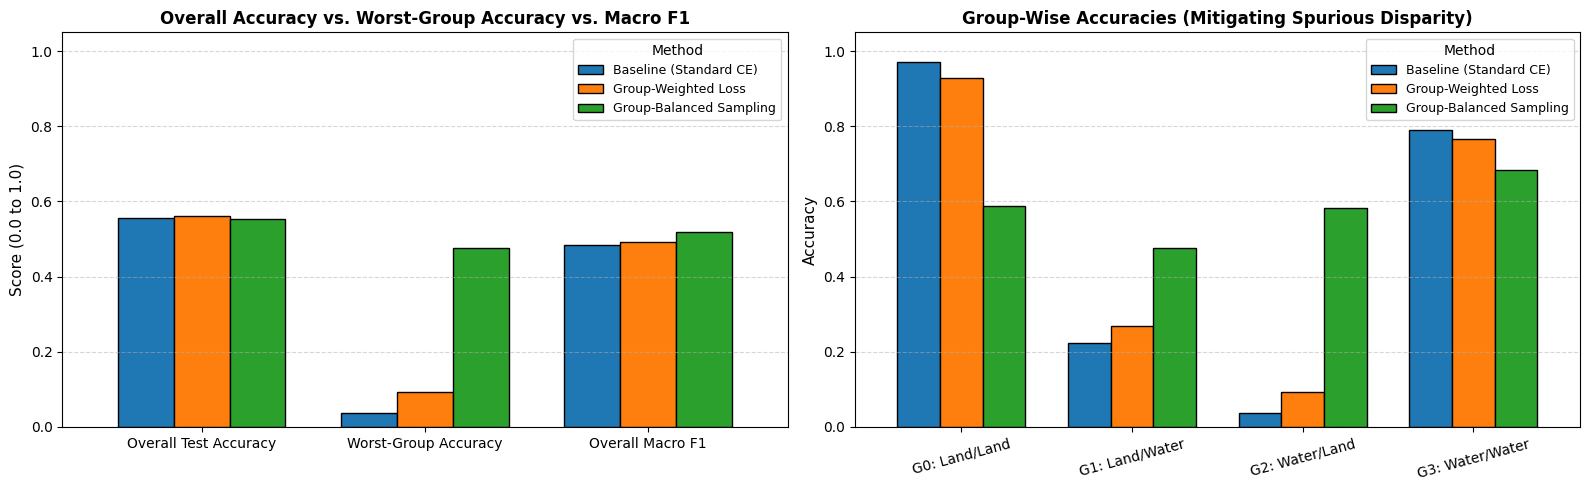

[+] Saved comparison plot to: results\all_three_models_comparison_chart.png


In [5]:
# 4. Publication-Ready Visual Comparison Charts
if all_results:
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    # Chart 1: Key Summary Metrics
    summary_metrics = ["Overall Test Accuracy", "Worst-Group Accuracy", "Overall Macro F1"]
    df_plot_summary = df_comparison[summary_metrics].T
    df_plot_summary.plot(kind="bar", ax=axes[0], width=0.75, edgecolor="black")
    axes[0].set_title("Overall Accuracy vs. Worst-Group Accuracy vs. Macro F1", fontsize=12, fontweight="bold")
    axes[0].set_ylabel("Score (0.0 to 1.0)", fontsize=11)
    axes[0].set_ylim(0, 1.05)
    axes[0].set_xticklabels(summary_metrics, rotation=0, fontsize=10)
    axes[0].grid(axis="y", linestyle="--", alpha=0.5)
    axes[0].legend(title="Method", fontsize=9)

    # Chart 2: Group Disparity Breakdown
    group_cols = [
        "Group 0 Acc (Landbird/Land)",
        "Group 1 Acc (Landbird/Water)",
        "Group 2 Acc (Waterbird/Land)",
        "Group 3 Acc (Waterbird/Water)"
    ]
    group_labels = ["G0: Land/Land", "G1: Land/Water", "G2: Water/Land", "G3: Water/Water"]
    df_groups = df_comparison[group_cols].copy()
    df_groups.columns = group_labels
    df_groups.T.plot(kind="bar", ax=axes[1], width=0.75, edgecolor="black")
    axes[1].set_title("Group-Wise Accuracies (Mitigating Spurious Disparity)", fontsize=12, fontweight="bold")
    axes[1].set_ylabel("Accuracy", fontsize=11)
    axes[1].set_ylim(0, 1.05)
    axes[1].set_xticklabels(group_labels, rotation=15, fontsize=10)
    axes[1].grid(axis="y", linestyle="--", alpha=0.5)
    axes[1].legend(title="Method", fontsize=9)

    plt.tight_layout()
    chart_path = Path("results/all_three_models_comparison_chart.png")
    plt.savefig(chart_path, dpi=300)
    plt.show()
    print(f"[+] Saved comparison plot to: {chart_path}")

CLASSIFICATION REPORT: BASELINE CNN
                     precision    recall  f1-score   support

 Landbird (Class 0)     0.7814    0.5967    0.6766      4510
Waterbird (Class 1)     0.2260    0.4136    0.2922      1284

           accuracy                         0.5561      5794
          macro avg     0.5037    0.5051    0.4844      5794
       weighted avg     0.6583    0.5561    0.5915      5794


CLASSIFICATION REPORT: GROUP-WEIGHTED CNN
                     precision    recall  f1-score   support

 Landbird (Class 0)     0.7866    0.5991    0.6802      4510
Waterbird (Class 1)     0.2336    0.4291    0.3025      1284

           accuracy                         0.5614      5794
          macro avg     0.5101    0.5141    0.4913      5794
       weighted avg     0.6641    0.5614    0.5965      5794


CLASSIFICATION REPORT: BALANCED SAMPLING CNN
                     precision    recall  f1-score   support

 Landbird (Class 0)     0.8357    0.5310    0.6494      4510
Waterbird (Cla

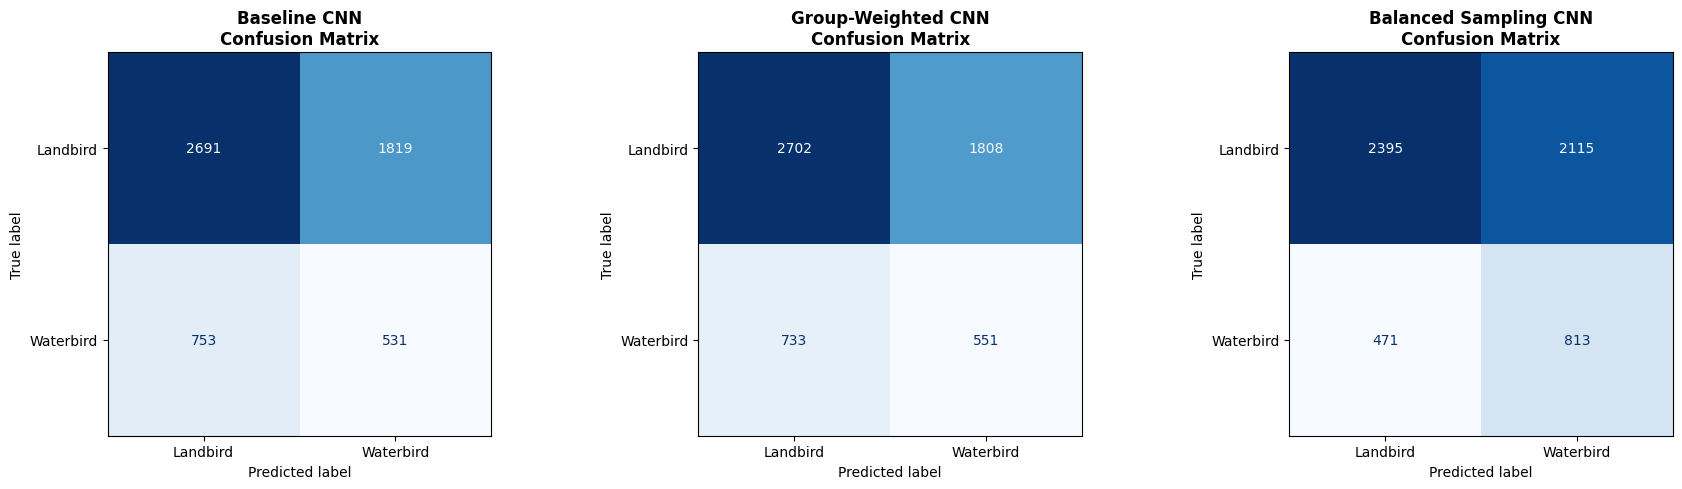

[+] Saved confusion matrix plots to: results\all_three_models_confusion_matrices.png


In [6]:
from pathlib import Path
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Class names corresponding to labels 0 and 1
target_names = ["Landbird (Class 0)", "Waterbird (Class 1)"]

models_to_inspect = [
    ("models/baseline_cnn.pt", "Baseline CNN"),
    ("models/weighted_cnn.pt", "Group-Weighted CNN"),
    ("models/balanced_sampling_cnn.pt", "Balanced Sampling CNN"),
]

# Set up side-by-side plots for the three confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (model_path, model_name) in enumerate(models_to_inspect):
    model_path = Path(model_path)
    if not model_path.exists():
        print(f"[-] Checkpoint not found: {model_path}")
        continue

    # 1. Load model checkpoint
    model = ShortcutScopeCNN(num_classes=2).to(DEVICE)
    checkpoint = torch.load(model_path, map_location=DEVICE, weights_only=True)
    model.load_state_dict(checkpoint)
    model.eval()

    # 2. Collect test predictions
    y_true, y_pred = [], []
    with torch.inference_mode():
        for images, labels, _ in test_loader:
            images = images.to(DEVICE)
            outputs = model(images)
            preds = outputs.argmax(dim=1)
            
            y_true.extend(labels.cpu().tolist())
            y_pred.extend(preds.cpu().tolist())

    # 3. Print the Classification Report (Precision, Recall, F1, Support)
    print("=" * 65)
    print(f"CLASSIFICATION REPORT: {model_name.upper()}")
    print("=" * 65)
    print(classification_report(y_true, y_pred, target_names=target_names, digits=4))
    print()

    # 4. Generate and Plot Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm, 
        display_labels=["Landbird", "Waterbird"]
    )
    disp.plot(ax=axes[idx], cmap="Blues", colorbar=False, values_format="d")
    axes[idx].set_title(f"{model_name}\nConfusion Matrix", fontsize=12, fontweight="bold")
    axes[idx].grid(False)

plt.tight_layout()
cm_plot_path = Path("results/all_three_models_confusion_matrices.png")
plt.savefig(cm_plot_path, dpi=300)
plt.show()

print(f"[+] Saved confusion matrix plots to: {cm_plot_path}")


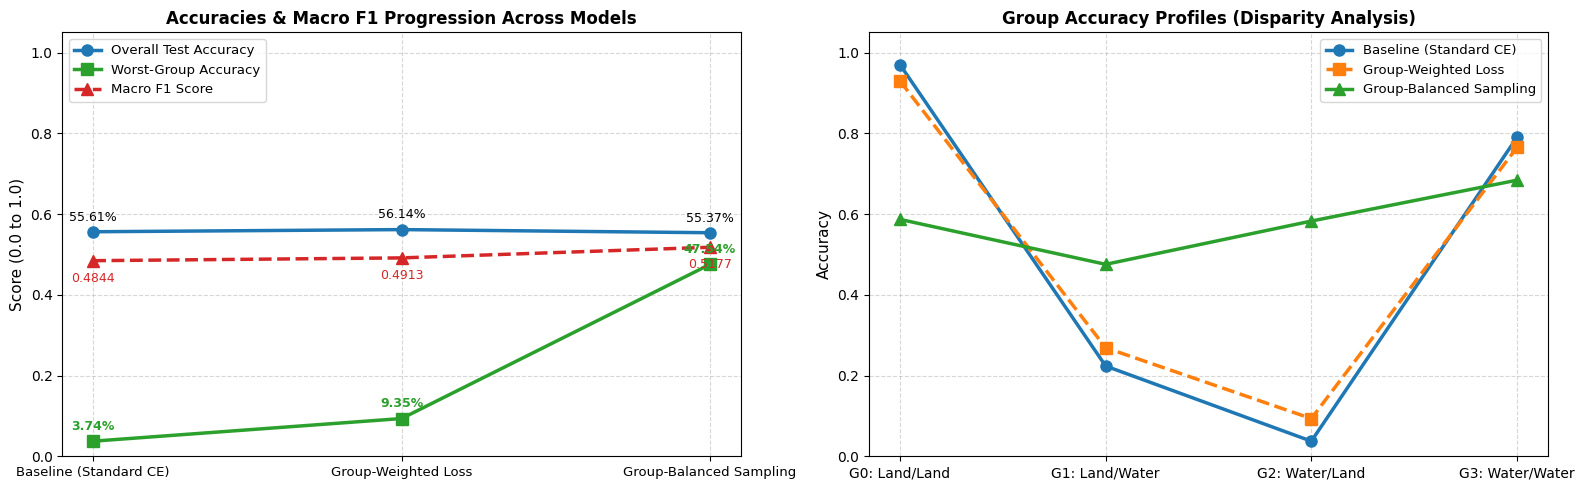

[+] Saved Test Accuracy & F1 Line Charts to: results\accuracies_and_f1_line_charts.png


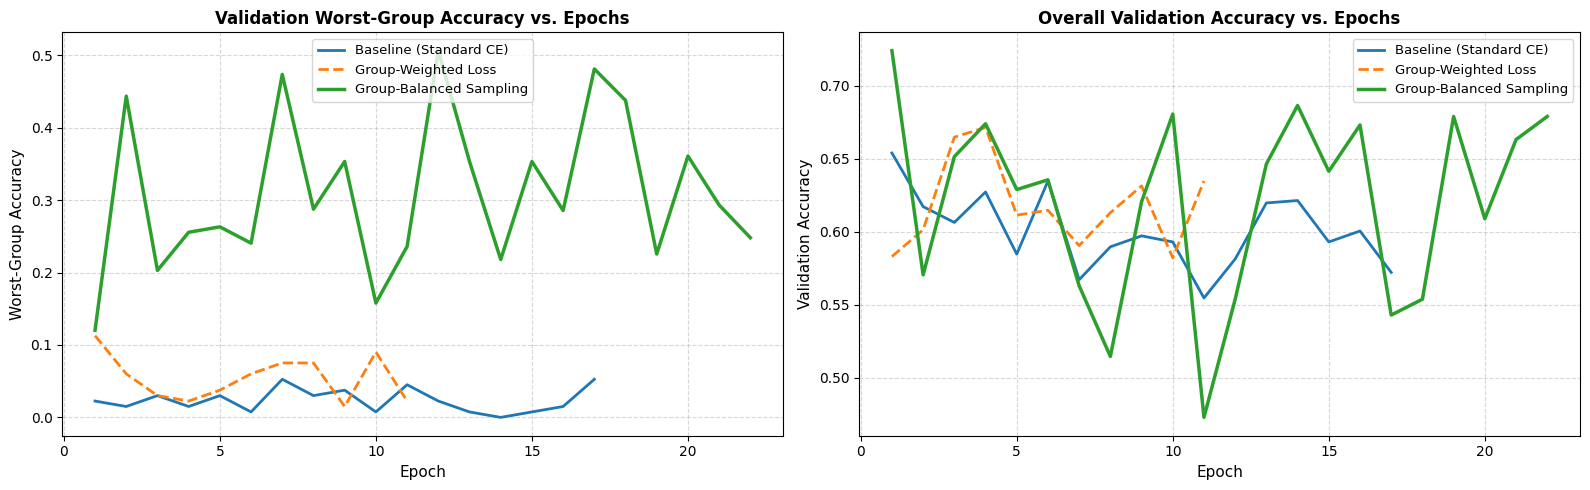

[+] Saved Epoch Trajectories Line Charts to: results\training_trajectories_line_charts.png


In [7]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================================
# 1. TEST SET COMPARISON: ACCURACIES & MACRO F1 LINE CHARTS
# =====================================================================
csv_path = Path("results/all_three_models_test_comparison.csv")
if not csv_path.exists():
    raise FileNotFoundError(f"Missing comparison CSV: {csv_path}. Run Cell 3 first!")

df = pd.read_csv(csv_path)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# ----------------- Subplot 1: Accuracies & Macro F1 Progression -----------------
models = df["Model"].tolist()
x = list(range(len(models)))

acc = df["Overall Test Accuracy"].values
wg = df["Worst-Group Accuracy"].values
f1 = df["Overall Macro F1"].values

axes[0].plot(x, acc, marker="o", linewidth=2.5, markersize=8, label="Overall Test Accuracy", color="#1f77b4")
axes[0].plot(x, wg, marker="s", linewidth=2.5, markersize=8, label="Worst-Group Accuracy", color="#2ca02c")
axes[0].plot(x, f1, marker="^", linewidth=2.5, markersize=8, linestyle="--", label="Macro F1 Score", color="#d62728")

# Annotate values directly on the points
for i in x:
    axes[0].annotate(f"{acc[i]:.2%}", (i, acc[i]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
    axes[0].annotate(f"{wg[i]:.2%}", (i, wg[i]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, fontweight="bold", color="#2ca02c")
    axes[0].annotate(f"{f1[i]:.4f}", (i, f1[i]), textcoords="offset points", xytext=(0, -15), ha="center", fontsize=9, color="#d62728")

axes[0].set_title("Accuracies & Macro F1 Progression Across Models", fontsize=12, fontweight="bold")
axes[0].set_xticks(x)
axes[0].set_xticklabels(models, fontsize=9.5)
axes[0].set_ylabel("Score (0.0 to 1.0)", fontsize=11)
axes[0].set_ylim(0, 1.05)
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(fontsize=9.5, loc="upper left")

# ----------------- Subplot 2: Group-Wise Accuracy Profile Line Chart -----------------
group_names = ["G0: Land/Land", "G1: Land/Water", "G2: Water/Land", "G3: Water/Water"]
group_cols = [
    "Group 0 Acc (Landbird/Land)",
    "Group 1 Acc (Landbird/Water)",
    "Group 2 Acc (Waterbird/Land)",
    "Group 3 Acc (Waterbird/Water)"
]

styles = [
    ("Baseline (Standard CE)", "o-", "#1f77b4"),
    ("Group-Weighted Loss", "s--", "#ff7f0e"),
    ("Group-Balanced Sampling", "^-", "#2ca02c")
]

for model_name, style, col in styles:
    row = df[df["Model"] == model_name]
    if not row.empty:
        vals = row[group_cols].values[0]
        axes[1].plot(group_names, vals, style, linewidth=2.5, markersize=8, label=model_name, color=col)

axes[1].set_title("Group Accuracy Profiles (Disparity Analysis)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Accuracy", fontsize=11)
axes[1].set_ylim(0, 1.05)
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(fontsize=9.5)

plt.tight_layout()
out_test_plot = Path("results/accuracies_and_f1_line_charts.png")
plt.savefig(out_test_plot, dpi=300)
plt.show()
print(f"[+] Saved Test Accuracy & F1 Line Charts to: {out_test_plot}")


# =====================================================================
# 2. TRAINING TRAJECTORIES OVER EPOCHS (VALIDATION CURVES)
# =====================================================================
b_hist = pd.read_csv("results/baseline_history.csv")
w_hist = pd.read_csv("results/weighted_history.csv")
bs_hist = pd.read_csv("results/balanced_sampling_history.csv")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot A: Worst-Group Validation Accuracy over Epochs
axes[0].plot(b_hist["epoch"], b_hist["val_worst_group_accuracy"], label="Baseline (Standard CE)", color="#1f77b4", linewidth=2)
axes[0].plot(w_hist["epoch"], w_hist["val_worst_group_accuracy"], label="Group-Weighted Loss", color="#ff7f0e", linewidth=2, linestyle="--")
axes[0].plot(bs_hist["epoch"], bs_hist["val_worst_group_accuracy"], label="Group-Balanced Sampling", color="#2ca02c", linewidth=2.5)

axes[0].set_title("Validation Worst-Group Accuracy vs. Epochs", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch", fontsize=11)
axes[0].set_ylabel("Worst-Group Accuracy", fontsize=11)
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(fontsize=9.5)

# Plot B: Overall Validation Accuracy over Epochs
axes[1].plot(b_hist["epoch"], b_hist["val_accuracy"], label="Baseline (Standard CE)", color="#1f77b4", linewidth=2)
axes[1].plot(w_hist["epoch"], w_hist["val_accuracy"], label="Group-Weighted Loss", color="#ff7f0e", linewidth=2, linestyle="--")
axes[1].plot(bs_hist["epoch"], bs_hist["val_accuracy"], label="Group-Balanced Sampling", color="#2ca02c", linewidth=2.5)

axes[1].set_title("Overall Validation Accuracy vs. Epochs", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch", fontsize=11)
axes[1].set_ylabel("Validation Accuracy", fontsize=11)
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(fontsize=9.5)

plt.tight_layout()
out_train_plot = Path("results/training_trajectories_line_charts.png")
plt.savefig(out_train_plot, dpi=300)
plt.show()
print(f"[+] Saved Epoch Trajectories Line Charts to: {out_train_plot}")
